In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"

folders = [
    "",
    "data",
    "data/raw",
    "data/raw/banfakenews",
    "data/raw/memes",
    "data/raw/fakeddit",
    "data/interim",
    "data/processed",
    "data/evidence",
    "outputs",
    "outputs/metrics",
    "outputs/figures",
    "outputs/predictions",
    "outputs/reports",
    "outputs/banglabert_baseline",
    "outputs/banglabert_weighted_colab",
    "models",
    "src",
    "src/data_collection",
    "src/preprocessing",
    "src/ocr",
    "src/models",
    "src/retrieval",
    "src/training",
    "src/evaluation",
    "src/explainability",
    "src/app",
    "notebooks",
    "scripts",
    "tests",
    "docs"
]

for folder in folders:
    path = os.path.join(PROJECT_ROOT, folder)
    os.makedirs(path, exist_ok=True)

print("CCEF-Net project folders created successfully.")
print("Project root:", PROJECT_ROOT)

CCEF-Net project folders created successfully.
Project root: /content/drive/MyDrive/CCEF-Net


In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"

for root, dirs, files in os.walk(PROJECT_ROOT):
    level = root.replace(PROJECT_ROOT, "").count(os.sep)
    indent = " " * 2 * level
    print(f"{indent}{os.path.basename(root)}/")

CCEF-Net/
  data/
    raw/
      banfakenews/
      memes/
      fakeddit/
    interim/
    processed/
    evidence/
  outputs/
    metrics/
    figures/
    predictions/
    reports/
    banglabert_baseline/
    banglabert_weighted_colab/
  models/
  src/
    data_collection/
    preprocessing/
    ocr/
    models/
    retrieval/
    training/
    evaluation/
    explainability/
    app/
  notebooks/
  scripts/
  tests/
  docs/


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not enabled. Go to Runtime -> Change runtime type -> T4 GPU")

CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [ ]:
from google.colab import files
import os
import shutil

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"
TARGET_DIR = os.path.join(PROJECT_ROOT, "data/processed")
TARGET_FILE = os.path.join(TARGET_DIR, "banfakenews_binary_clean.csv")

os.makedirs(TARGET_DIR, exist_ok=True)

print("Please select your banfakenews_binary_clean.csv file...")

uploaded = files.upload()

for filename in uploaded.keys():
    if filename == "banfakenews_binary_clean.csv":
        shutil.move(filename, TARGET_FILE)
        print("File moved to:", TARGET_FILE)
    else:
        print("Uploaded file name is different:", filename)
        print("Expected file name: banfakenews_binary_clean.csv")

Please select your banfakenews_binary_clean.csv file...


Saving banfakenews_binary_clean.csv to banfakenews_binary_clean.csv
File moved to: /content/drive/MyDrive/CCEF-Net/data/processed/banfakenews_binary_clean.csv


In [ ]:
import os
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"
DATA_FILE = os.path.join(PROJECT_ROOT, "data/processed/banfakenews_binary_clean.csv")

print("File exists:", os.path.exists(DATA_FILE))

if os.path.exists(DATA_FILE):
    print("File size (MB):", round(os.path.getsize(DATA_FILE) / (1024 * 1024), 2))

    df = pd.read_csv(DATA_FILE)

    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    print("\nLabel distribution:")
    print(df["label"].value_counts())

    print("\nMissing values:")
    print(df.isnull().sum())

File exists: True
File size (MB): 552.56
Rows: 58621
Columns: ['headline', 'content', 'label', 'headline_clean', 'content_clean']

Label distribution:
label
1    48677
0     9944
Name: count, dtype: int64

Missing values:
headline          0
content           0
label             0
headline_clean    0
content_clean     0
dtype: int64


In [ ]:
!pip install -q "transformers==4.46.3" "datasets==3.1.0" "accelerate==1.1.1" "peft==0.13.2" "sentencepiece==0.2.0" "sentence-transformers==3.2.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for sentencepiece (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for sentencepiece
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> sentencepiece


In [ ]:
# ==========================================================
# CCEF-Net: BanglaBERT Weighted Baseline Training on Colab T4
# ==========================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

# ----------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------

SEED = 42
MODEL_NAME = "csebuetnlp/banglabert"

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"
DATA_FILE = os.path.join(
    PROJECT_ROOT,
    "data/processed/banfakenews_binary_clean.csv"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "outputs/banglabert_weighted_colab"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Project root:", PROJECT_ROOT)
print("Dataset file:", DATA_FILE)
print("Output directory:", OUTPUT_DIR)

# ----------------------------------------------------------
# 2. Load dataset
# ----------------------------------------------------------

print("\nLoading dataset...")

df = pd.read_csv(DATA_FILE)

df["text"] = (
    df["headline_clean"].astype(str)
    + " [SEP] "
    + df["content_clean"].astype(str)
)

print("Total rows:", len(df))
print("Columns:", list(df.columns))

print("\nOriginal label distribution:")
print(df["label"].value_counts())

# ----------------------------------------------------------
# 3. Train / validation / test split
# ----------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("\nTrain size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))

print("\nTrain label distribution:")
print(train_df["label"].value_counts())

print("\nValidation label distribution:")
print(val_df["label"].value_counts())

print("\nTest label distribution:")
print(test_df["label"].value_counts())

# ----------------------------------------------------------
# 4. Tokenizer and dataset
# ----------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class NewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts.tolist()
        self.labels = labels.tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = int(self.labels[idx])

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }

train_dataset = NewsDataset(
    train_df["text"],
    train_df["label"],
    tokenizer
)

val_dataset = NewsDataset(
    val_df["text"],
    val_df["label"],
    tokenizer
)

test_dataset = NewsDataset(
    test_df["text"],
    test_df["label"],
    tokenizer
)

# ----------------------------------------------------------
# 5. Model
# ----------------------------------------------------------

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# ----------------------------------------------------------
# 6. Class weights for imbalance
# ----------------------------------------------------------

class_counts = train_df["label"].value_counts().sort_index()
total_samples = len(train_df)

class_weights = []
for i in range(2):
    weight = total_samples / (2 * class_counts[i])
    class_weights.append(weight)

class_weights = torch.tensor(class_weights, dtype=torch.float)

print("\nClass counts:")
print(class_counts)

print("\nClass weights:")
print(class_weights)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_weights = class_weights.to(device)

print("\nUsing device:", device)

# ----------------------------------------------------------
# 7. Weighted Trainer
# ----------------------------------------------------------

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        loss_fct = nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        loss = loss_fct(logits, labels)

        return (loss, outputs) if return_outputs else loss

# ----------------------------------------------------------
# 8. Metrics
# ----------------------------------------------------------

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
        "weighted_f1": f1_score(labels, predictions, average="weighted"),
        "fake_recall": recall_score(labels, predictions, pos_label=0),
        "fake_f1": f1_score(labels, predictions, pos_label=0)
    }

# ----------------------------------------------------------
# 9. Training arguments
# ----------------------------------------------------------

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=500,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=100,
    fp16=True,
    report_to="none"
)

# ----------------------------------------------------------
# 10. Trainer
# ----------------------------------------------------------

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

# ----------------------------------------------------------
# 11. Train
# ----------------------------------------------------------

print("\nStarting weighted BanglaBERT training on Colab T4...")

trainer.train()

# ----------------------------------------------------------
# 12. Evaluation
# ----------------------------------------------------------

print("\nEvaluating on validation set...")
val_metrics = trainer.evaluate(eval_dataset=val_dataset)
print(val_metrics)

print("\nEvaluating on test set...")
test_metrics = trainer.evaluate(eval_dataset=test_dataset)
print(test_metrics)

# ----------------------------------------------------------
# 13. Test predictions
# ----------------------------------------------------------

print("\nGenerating test predictions...")

predictions = trainer.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=1)
true_labels = predictions.label_ids

print("\nClassification Report:")
print(classification_report(
    true_labels,
    preds,
    target_names=["Fake", "Authentic"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(true_labels, preds))

# ----------------------------------------------------------
# 14. Save final model and predictions
# ----------------------------------------------------------

final_model_dir = os.path.join(OUTPUT_DIR, "final_model")

trainer.save_model(final_model_dir)
tokenizer.save_pretrained(final_model_dir)

prediction_df = pd.DataFrame({
    "true_label": true_labels,
    "predicted_label": preds
})

prediction_file = os.path.join(
    OUTPUT_DIR,
    "test_predictions.csv"
)

prediction_df.to_csv(prediction_file, index=False)

print("\nFinal model saved to:", final_model_dir)
print("Test predictions saved to:", prediction_file)
print("\nTraining complete.")

Project root: /content/drive/MyDrive/CCEF-Net
Dataset file: /content/drive/MyDrive/CCEF-Net/data/processed/banfakenews_binary_clean.csv
Output directory: /content/drive/MyDrive/CCEF-Net/outputs/banglabert_weighted_colab

Loading dataset...
Total rows: 58621
Columns: ['headline', 'content', 'label', 'headline_clean', 'content_clean', 'text']

Original label distribution:
label
1    48677
0     9944
Name: count, dtype: int64

Train size: 41034
Validation size: 8793
Test size: 8794

Train label distribution:
label
1    34073
0     6961
Name: count, dtype: int64

Validation label distribution:
label
1    7302
0    1491
Name: count, dtype: int64

Test label distribution:
label
1    7302
0    1492
Name: count, dtype: int64


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Class counts:
label
0     6961
1    34073
Name: count, dtype: int64

Class weights:
tensor([2.9474, 0.6021])

Using device: cuda

Starting weighted BanglaBERT training on Colab T4...


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1,Fake Recall,Fake F1
1,0.296656,0.319114,0.955419,0.913131,0.953186,0.759893,0.852521
2,0.249905,0.324502,0.958262,0.920361,0.956669,0.791415,0.865420


...

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1,Fake Recall,Fake F1
0.249905,0.328120,2,0.958381,0.920316,0.956702,0.787534,0.865243


{'eval_loss': 0.32812023162841797, 'eval_accuracy': 0.9583807141232659, 'eval_macro_f1': 0.920316499519513, 'eval_weighted_f1': 0.9567023315115835, 'eval_fake_recall': 0.7875335120643432, 'eval_fake_f1': 0.8652430044182622}

Generating test predictions...



Classification Report:
              precision    recall  f1-score   support

        Fake       0.96      0.79      0.87      1492
   Authentic       0.96      0.99      0.98      7302

    accuracy                           0.96      8794
   macro avg       0.96      0.89      0.92      8794
weighted avg       0.96      0.96      0.96      8794


Confusion Matrix:
[[1175  317]
 [  49 7253]]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Final model saved to: /content/drive/MyDrive/CCEF-Net/outputs/banglabert_weighted_colab/final_model
Test predictions saved to: /content/drive/MyDrive/CCEF-Net/outputs/banglabert_weighted_colab/test_predictions.csv

Training complete.


In [ ]:
# ==========================================================
# CCEF-Net: XLM-RoBERTa Baseline Training on Colab T4
# ==========================================================

import os
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

SEED = 42
MODEL_NAME = "xlm-roberta-base"

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"
DATA_FILE = os.path.join(
    PROJECT_ROOT,
    "data/processed/banfakenews_binary_clean.csv"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "outputs/xlmroberta_baseline_colab"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Loading dataset...")
df = pd.read_csv(DATA_FILE)

df["text"] = (
    df["headline_clean"].astype(str)
    + " </s> "
    + df["content_clean"].astype(str)
)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class NewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts.tolist()
        self.labels = labels.tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = int(self.labels[idx])

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }

train_dataset = NewsDataset(train_df["text"], train_df["label"], tokenizer)
val_dataset = NewsDataset(val_df["text"], val_df["label"], tokenizer)
test_dataset = NewsDataset(test_df["text"], test_df["label"], tokenizer)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
        "weighted_f1": f1_score(labels, predictions, average="weighted"),
        "fake_recall": recall_score(labels, predictions, pos_label=0),
        "fake_f1": f1_score(labels, predictions, pos_label=0)
    }

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=500,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=100,
    fp16=True,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("\nStarting XLM-RoBERTa baseline training on Colab T4...")
trainer.train()

print("\nEvaluating on validation set...")
val_metrics = trainer.evaluate(eval_dataset=val_dataset)
print(val_metrics)

print("\nEvaluating on test set...")
test_metrics = trainer.evaluate(eval_dataset=test_dataset)
print(test_metrics)

print("\nGenerating test predictions...")
predictions = trainer.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=1)
true_labels = predictions.label_ids

print("\nClassification Report:")
print(classification_report(
    true_labels,
    preds,
    target_names=["Fake", "Authentic"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(true_labels, preds))

final_model_dir = os.path.join(OUTPUT_DIR, "final_model")
trainer.save_model(final_model_dir)
tokenizer.save_pretrained(final_model_dir)

prediction_df = pd.DataFrame({
    "true_label": true_labels,
    "predicted_label": preds
})

prediction_file = os.path.join(
    OUTPUT_DIR,
    "test_predictions.csv"
)

prediction_df.to_csv(prediction_file, index=False)

print("\nFinal model saved to:", final_model_dir)
print("Test predictions saved to:", prediction_file)
print("\nXLM-R baseline training complete.")

Loading dataset...
Train size: 41034
Validation size: 8793
Test size: 8794


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

...

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1,Fake Recall,Fake F1
0.154559,0.168841,2,0.957926,0.917238,0.955577,0.756702,0.859209


{'eval_loss': 0.16884073615074158, 'eval_accuracy': 0.9579258585399136, 'eval_macro_f1': 0.9172379516356148, 'eval_weighted_f1': 0.9555767027082672, 'eval_fake_recall': 0.7567024128686327, 'eval_fake_f1': 0.8592085235920852}

Generating test predictions...



Classification Report:
              precision    recall  f1-score   support

        Fake       0.99      0.76      0.86      1492
   Authentic       0.95      1.00      0.98      7302

    accuracy                           0.96      8794
   macro avg       0.97      0.88      0.92      8794
weighted avg       0.96      0.96      0.96      8794


Confusion Matrix:
[[1129  363]
 [   7 7295]]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Final model saved to: /content/drive/MyDrive/CCEF-Net/outputs/xlmroberta_baseline_colab/final_model
Test predictions saved to: /content/drive/MyDrive/CCEF-Net/outputs/xlmroberta_baseline_colab/test_predictions.csv

XLM-R baseline training complete.



MODEL: BanglaBERT Standard
Prediction file not found: /content/drive/MyDrive/CCEF-Net/outputs/banglabert_baseline/test_predictions.csv

MODEL: BanglaBERT Weighted
Accuracy        : 0.9584
Macro F1        : 0.9203
Weighted F1     : 0.9567
Fake Precision  : 0.9600
Fake Recall     : 0.7875
Fake F1         : 0.8652

Confusion Matrix:
[[1175  317]
 [  49 7253]]

MODEL: XLM-RoBERTa
Accuracy        : 0.9579
Macro F1        : 0.9172
Weighted F1     : 0.9556
Fake Precision  : 0.9938
Fake Recall     : 0.7567
Fake F1         : 0.8592

Confusion Matrix:
[[1129  363]
 [   7 7295]]

FINAL BASELINE COMPARISON
              Model  Accuracy  Macro_F1  Weighted_F1  Fake_Precision  Fake_Recall  Fake_F1
BanglaBERT Weighted  0.958381  0.920316     0.956702        0.959967     0.787534 0.865243
        XLM-RoBERTa  0.957926  0.917238     0.955577        0.993838     0.756702 0.859209

Comparison table saved to: /content/drive/MyDrive/CCEF-Net/outputs/metrics/baseline_comparison.csv


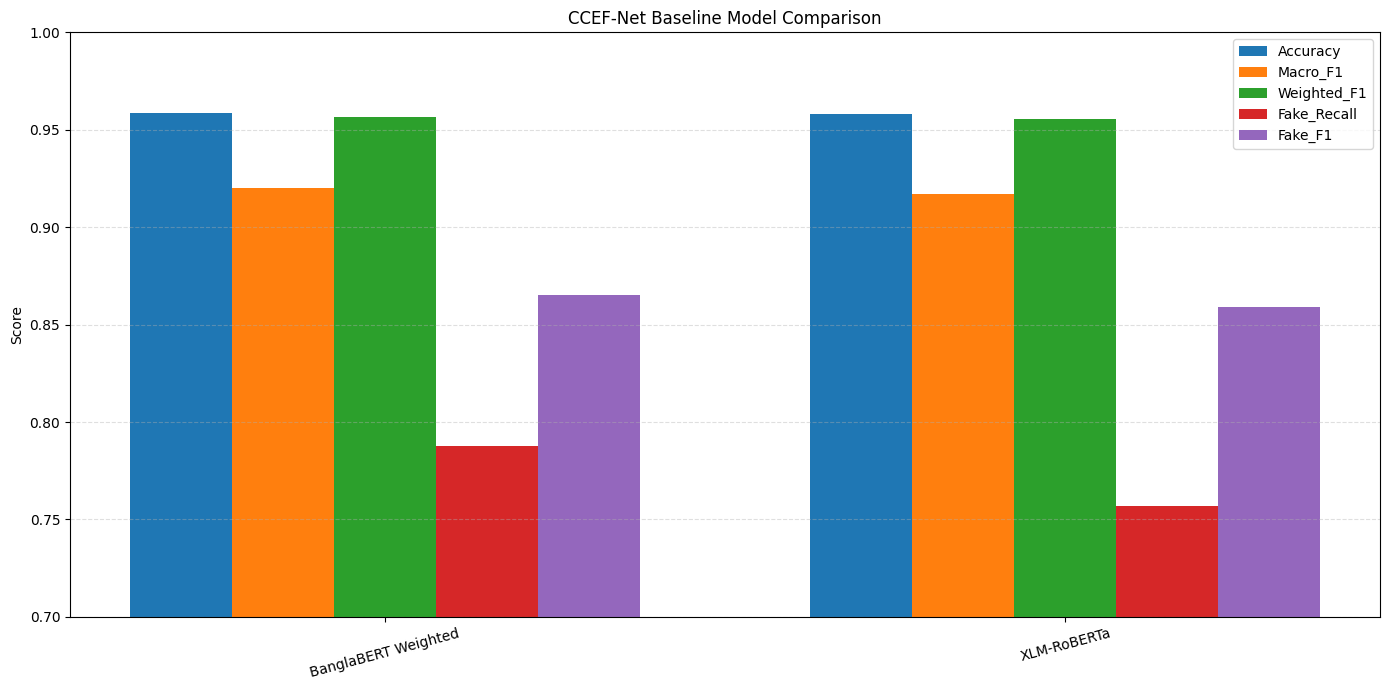

Comparison plot saved to: /content/drive/MyDrive/CCEF-Net/outputs/metrics/baseline_comparison.png


In [ ]:
# ==========================================================
# CCEF-Net: Baseline Results Comparison
# ==========================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"

MODEL_RESULTS = {
    "BanglaBERT Standard": os.path.join(
        PROJECT_ROOT,
        "outputs/banglabert_baseline/test_predictions.csv"
    ),
    "BanglaBERT Weighted": os.path.join(
        PROJECT_ROOT,
        "outputs/banglabert_weighted_colab/test_predictions.csv"
    ),
    "XLM-RoBERTa": os.path.join(
        PROJECT_ROOT,
        "outputs/xlmroberta_baseline_colab/test_predictions.csv"
    )
}

OUTPUT_DIR = os.path.join(PROJECT_ROOT, "outputs/metrics")
os.makedirs(OUTPUT_DIR, exist_ok=True)

all_results = []
confusion_matrices = {}

for model_name, prediction_file in MODEL_RESULTS.items():
    print("\n" + "=" * 60)
    print("MODEL:", model_name)
    print("=" * 60)

    if not os.path.exists(prediction_file):
        print("Prediction file not found:", prediction_file)
        continue

    df = pd.read_csv(prediction_file)

    true_labels = df["true_label"]
    predicted_labels = df["predicted_label"]

    accuracy = accuracy_score(true_labels, predicted_labels)
    macro_f1 = f1_score(true_labels, predicted_labels, average="macro")
    weighted_f1 = f1_score(true_labels, predicted_labels, average="weighted")
    fake_precision = precision_score(true_labels, predicted_labels, pos_label=0)
    fake_recall = recall_score(true_labels, predicted_labels, pos_label=0)
    fake_f1 = f1_score(true_labels, predicted_labels, pos_label=0)

    cm = confusion_matrix(true_labels, predicted_labels)
    confusion_matrices[model_name] = cm

    print(f"Accuracy        : {accuracy:.4f}")
    print(f"Macro F1        : {macro_f1:.4f}")
    print(f"Weighted F1     : {weighted_f1:.4f}")
    print(f"Fake Precision  : {fake_precision:.4f}")
    print(f"Fake Recall     : {fake_recall:.4f}")
    print(f"Fake F1         : {fake_f1:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    all_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
        "Fake_Precision": fake_precision,
        "Fake_Recall": fake_recall,
        "Fake_F1": fake_f1
    })

results_df = pd.DataFrame(all_results)

print("\n" + "=" * 60)
print("FINAL BASELINE COMPARISON")
print("=" * 60)
print(results_df.to_string(index=False))

comparison_file = os.path.join(
    OUTPUT_DIR,
    "baseline_comparison.csv"
)

results_df.to_csv(comparison_file, index=False)
print("\nComparison table saved to:", comparison_file)

# ----------------------------------------------------------
# Plot comparison
# ----------------------------------------------------------

metrics_to_plot = [
    "Accuracy",
    "Macro_F1",
    "Weighted_F1",
    "Fake_Recall",
    "Fake_F1"
]

plt.figure(figsize=(14, 7))

x = np.arange(len(results_df["Model"]))
width = 0.15

for i, metric in enumerate(metrics_to_plot):
    plt.bar(
        x + i * width,
        results_df[metric],
        width,
        label=metric
    )

plt.xticks(
    x + width * 2,
    results_df["Model"],
    rotation=15
)

plt.ylim(0.70, 1.00)
plt.ylabel("Score")
plt.title("CCEF-Net Baseline Model Comparison")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plot_file = os.path.join(
    OUTPUT_DIR,
    "baseline_comparison.png"
)

plt.savefig(plot_file, dpi=300)
plt.show()

print("Comparison plot saved to:", plot_file)

In [ ]:
# ==========================================================
# CCEF-Net TASK 8.1
# Inspect official Fakeddit GitHub repository
# ==========================================================

import requests

GITHUB_API = "https://api.github.com/repos/entitize/Fakeddit/contents"

print("Checking official Fakeddit GitHub repository...")
print("Repository:", GITHUB_API)

response = requests.get(GITHUB_API, timeout=60)

print("\nStatus code:", response.status_code)

if response.status_code == 200:
    items = response.json()

    print("\nRepository root contents:")

    for item in items:
        print("\nName:", item["name"])
        print("Type:", item["type"])
        print("Path:", item["path"])
        print("Download URL:", item.get("download_url", "N/A"))
else:
    print("Could not access repository.")
    print(response.text)

Checking official Fakeddit GitHub repository...
Repository: https://api.github.com/repos/entitize/Fakeddit/contents

Status code: 200

Repository root contents:

Name: .gitattributes
Type: file
Path: .gitattributes
Download URL: https://raw.githubusercontent.com/entitize/Fakeddit/master/.gitattributes

Name: .gitignore
Type: file
Path: .gitignore
Download URL: https://raw.githubusercontent.com/entitize/Fakeddit/master/.gitignore

Name: README.md
Type: file
Path: README.md
Download URL: https://raw.githubusercontent.com/entitize/Fakeddit/master/README.md

Name: image_downloader.py
Type: file
Path: image_downloader.py
Download URL: https://raw.githubusercontent.com/entitize/Fakeddit/master/image_downloader.py

Name: requirements.txt
Type: file
Path: requirements.txt
Download URL: https://raw.githubusercontent.com/entitize/Fakeddit/master/requirements.txt


In [ ]:
# ==========================================================
# CCEF-Net TASK 8.1
# Inspect Fakeddit dataset folder
# ==========================================================

import requests

DATASET_API = "https://api.github.com/repos/entitize/Fakeddit/contents/dataset"

print("Checking Fakeddit dataset folder...")
print("URL:", DATASET_API)

response = requests.get(DATASET_API, timeout=60)

print("\nStatus code:", response.status_code)

if response.status_code == 200:
    items = response.json()

    print("\nDataset folder contents:")

    for item in items:
        print("\nName:", item["name"])
        print("Type:", item["type"])
        print("Path:", item["path"])
        print("Download URL:", item.get("download_url", "N/A"))
        print("Size:", item.get("size", "N/A"))
else:
    print("Could not access dataset folder.")
    print(response.text)

Checking Fakeddit dataset folder...
URL: https://api.github.com/repos/entitize/Fakeddit/contents/dataset

Status code: 404
Could not access dataset folder.
{"message":"Not Found","documentation_url":"https://docs.github.com/rest/repos/contents#get-repository-content","status":"404"}


In [ ]:
# ==========================================================
# CCEF-Net TASK 8.2
# Download and inspect Fakeddit README
# ==========================================================

import requests
import re

README_URL = "https://raw.githubusercontent.com/entitize/Fakeddit/master/README.md"

print("Downloading Fakeddit README...")
print("URL:", README_URL)

response = requests.get(README_URL, timeout=60)

print("Status code:", response.status_code)

if response.status_code == 200:
    readme_text = response.text

    print("\nREADME length:", len(readme_text))

    print("\n" + "=" * 60)
    print("README CONTENT")
    print("=" * 60)
    print(readme_text[:5000])

    print("\n" + "=" * 60)
    print("FOUND LINKS")
    print("=" * 60)

    links = re.findall(r"https?://[^\s\)\]\>]+", readme_text)

    for link in links:
        print(link)

else:
    print("Could not download README.")
    print(response.text)

URL: https://raw.githubusercontent.com/entitize/Fakeddit/master/README.md
Status code: 200

README length: 2733

README CONTENT
# Fakeddit

Kai Nakamura, Sharon Levy, and William Yang Wang. 2020. r/Fakeddit: A New Multimodal Benchmark Dataset for Fine-grained Fake News Detection

Website: https://fakeddit.netlify.app/

Codalab Competition: https://competitions.codalab.org/competitions/25337

Paper: https://arxiv.org/abs/1911.03854

Our lab: http://nlp.cs.ucsb.edu/index.html



## Getting Started

Follow the instructions to download the dataset. You can download text, metadata, comment data, and image data.

Note that released test set is public. Private test set is used for leaderboard (coming soon).

Please read the `Usage` section. It is important.  

Please let us know if you encounter any problems by opening an issue or by directly contacting us.

### Installation

#### Download text and metadata
Please read the USAGE section before using or downloading. 
Download the v2.0 dataset 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==========================================================
# CCEF-Net TASK 8.3
# Verify uploaded Fakeddit metadata files
# ==========================================================

import os
import glob
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"
FAKEDDIT_DIR = os.path.join(PROJECT_ROOT, "data/raw/fakeddit")

print("Checking Fakeddit folder...")
print(FAKEDDIT_DIR)

all_files = os.listdir(FAKEDDIT_DIR)

print("\nAll files in folder:")
for file in all_files:
    print("-", file)

tsv_files = glob.glob(os.path.join(FAKEDDIT_DIR, "*.tsv"))

print("\nFound TSV files:")
for file in tsv_files:
    print("-", file)

if not tsv_files:
    print("\nNo TSV files found yet.")
else:
    for file_path in tsv_files:
        print("\n" + "=" * 60)
        print("FILE:", os.path.basename(file_path))
        print("=" * 60)

        try:
            df = pd.read_csv(file_path, sep="\t")

            print("Rows:", len(df))
            print("Columns:", len(df.columns))
            print("Column names:", list(df.columns))

            print("\nFirst 3 rows:")
            print(df.head(3))

            print("\nLabel-related columns:")
            for col in df.columns:
                if "label" in col.lower():
                    print(f"\n{col}:")
                    print(df[col].value_counts())

        except Exception as e:
            print("Could not read file:", file_path)
            print(e)

Checking Fakeddit folder...
/content/drive/MyDrive/CCEF-Net/data/raw/fakeddit

All files in folder:
- multimodal_test_public.tsv
- multimodal_validate.tsv
- multimodal_train.tsv

Found TSV files:
- /content/drive/MyDrive/CCEF-Net/data/raw/fakeddit/multimodal_test_public.tsv
- /content/drive/MyDrive/CCEF-Net/data/raw/fakeddit/multimodal_validate.tsv
- /content/drive/MyDrive/CCEF-Net/data/raw/fakeddit/multimodal_train.tsv

FILE: multimodal_test_public.tsv
Rows: 59319
Columns: 16
Column names: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

First 3 rows:
         author                                        clean_title  \
0  trustbytrust                                          stargazer   
1           NaN                                               yeah   
2      chaseoes  pd phoenix car thief gets instructions from yo..

In [ ]:
# ==========================================================
# CCEF-Net TASK 9
# Create small balanced Fakeddit multimodal subset
# ==========================================================

import os
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"
FAKEDDIT_DIR = os.path.join(PROJECT_ROOT, "data/raw/fakeddit")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "data/processed/fakeddit_pilot")

os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_FILE = os.path.join(FAKEDDIT_DIR, "multimodal_train.tsv")
VAL_FILE = os.path.join(FAKEDDIT_DIR, "multimodal_validate.tsv")
TEST_FILE = os.path.join(FAKEDDIT_DIR, "multimodal_test_public.tsv")

print("Loading Fakeddit metadata...")

train_df = pd.read_csv(TRAIN_FILE, sep="\t")
val_df = pd.read_csv(VAL_FILE, sep="\t")
test_df = pd.read_csv(TEST_FILE, sep="\t")

print("Train rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

# Keep only useful columns
useful_columns = [
    "id",
    "clean_title",
    "image_url",
    "hasImage",
    "2_way_label"
]

train_df = train_df[useful_columns].copy()
val_df = val_df[useful_columns].copy()
test_df = test_df[useful_columns].copy()

# Keep only samples with image and non-empty title
train_df = train_df[
    (train_df["hasImage"] == True) &
    (train_df["clean_title"].notna()) &
    (train_df["clean_title"].str.strip().str.len() > 0) &
    (train_df["image_url"].notna())
]

val_df = val_df[
    (val_df["hasImage"] == True) &
    (val_df["clean_title"].notna()) &
    (val_df["clean_title"].str.strip().str.len() > 0) &
    (val_df["image_url"].notna())
]

test_df = test_df[
    (test_df["hasImage"] == True) &
    (test_df["clean_title"].notna()) &
    (test_df["clean_title"].str.strip().str.len() > 0) &
    (test_df["image_url"].notna())
]

print("\nAfter filtering:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


def create_balanced_subset(df, per_class, seed=42):
    return (
        df.groupby("2_way_label", group_keys=False)
        .apply(lambda x: x.sample(n=per_class, random_state=seed))
        .reset_index(drop=True)
    )

print("\nCreating balanced pilot subsets...")

train_pilot = create_balanced_subset(train_df, per_class=3000)
val_pilot = create_balanced_subset(val_df, per_class=500)
test_pilot = create_balanced_subset(test_df, per_class=500)

print("\nTrain pilot size:", len(train_pilot))
print("Validation pilot size:", len(val_pilot))
print("Test pilot size:", len(test_pilot))

print("\nTrain pilot label distribution:")
print(train_pilot["2_way_label"].value_counts())

print("\nValidation pilot label distribution:")
print(val_pilot["2_way_label"].value_counts())

print("\nTest pilot label distribution:")
print(test_pilot["2_way_label"].value_counts())

train_path = os.path.join(OUTPUT_DIR, "fakeddit_pilot_train.csv")
val_path = os.path.join(OUTPUT_DIR, "fakeddit_pilot_validation.csv")
test_path = os.path.join(OUTPUT_DIR, "fakeddit_pilot_test.csv")

train_pilot.to_csv(train_path, index=False)
val_pilot.to_csv(val_path, index=False)
test_pilot.to_csv(test_path, index=False)

print("\nSaved files:")
print(train_path)
print(val_path)
print(test_path)

print("\nTASK 9 complete.")

Loading Fakeddit metadata...
Train rows: 564000
Validation rows: 59342
Test rows: 59319

After filtering:
Train: 562466
Validation: 59169
Test: 59163

Creating balanced pilot subsets...

Train pilot size: 6000
Validation pilot size: 1000
Test pilot size: 1000

Train pilot label distribution:
2_way_label
0    3000
1    3000
Name: count, dtype: int64

Validation pilot label distribution:
2_way_label
0    500
1    500
Name: count, dtype: int64

Test pilot label distribution:
2_way_label
0    500
1    500
Name: count, dtype: int64

Saved files:
/content/drive/MyDrive/CCEF-Net/data/processed/fakeddit_pilot/fakeddit_pilot_train.csv
/content/drive/MyDrive/CCEF-Net/data/processed/fakeddit_pilot/fakeddit_pilot_validation.csv
/content/drive/MyDrive/CCEF-Net/data/processed/fakeddit_pilot/fakeddit_pilot_test.csv

TASK 9 complete.


/tmp/ipykernel_903/2934972871.py:73: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=per_class, random_state=seed))
/tmp/ipykernel_903/2934972871.py:73: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=per_class, random_state=seed))
/tmp/ipykernel_903/2934972871.py:73: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavio

In [ ]:
# ==========================================================
# CCEF-Net TASK 10
# Download 50 Fakeddit pilot images
# ==========================================================

import os
import time
import random
import requests
import pandas as pd
from PIL import Image
from io import BytesIO

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"
PILOT_FILE = os.path.join(
    PROJECT_ROOT,
    "data/processed/fakeddit_pilot/fakeddit_pilot_train.csv"
)

IMAGE_DIR = os.path.join(
    PROJECT_ROOT,
    "data/raw/fakeddit/images_pilot"
)

os.makedirs(IMAGE_DIR, exist_ok=True)

print("Loading pilot train metadata...")
df = pd.read_csv(PILOT_FILE)

print("Total pilot train samples:", len(df))

# Take first 25 fake and 25 real images
fake_df = df[df["2_way_label"] == 0].head(25)
real_df = df[df["2_way_label"] == 1].head(25)

pilot_df = pd.concat([fake_df, real_df]).reset_index(drop=True)

print("Pilot download samples:", len(pilot_df))
print("Image directory:", IMAGE_DIR)

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"
}

download_log = []

for index, row in pilot_df.iterrows():
    sample_id = str(row["id"])
    image_url = str(row["image_url"])
    label = int(row["2_way_label"])

    image_path = os.path.join(IMAGE_DIR, f"{sample_id}.jpg")

    record = {
        "id": sample_id,
        "image_url": image_url,
        "label": label,
        "status": "PENDING",
        "error": "",
        "image_path": "",
        "width": 0,
        "height": 0
    }

    try:
        response = requests.get(
            image_url,
            headers=headers,
            timeout=15
        )

        if response.status_code != 200:
            record["status"] = "FAILED"
            record["error"] = f"HTTP {response.status_code}"
            download_log.append(record)
            continue

        image = Image.open(BytesIO(response.content)).convert("RGB")
        image.save(image_path, "JPEG", quality=90)

        record["status"] = "SUCCESS"
        record["image_path"] = image_path
        record["width"] = image.width
        record["height"] = image.height

    except Exception as e:
        record["status"] = "FAILED"
        record["error"] = str(e)

    download_log.append(record)

    print(f"[{index + 1}/{len(pilot_df)}] {record['status']} - {sample_id}")

    time.sleep(0.5)

log_df = pd.DataFrame(download_log)

log_path = os.path.join(
    PROJECT_ROOT,
    "data/raw/fakeddit/fakeddit_pilot_download_log.csv"
)

log_df.to_csv(log_path, index=False)

success_count = (log_df["status"] == "SUCCESS").sum()
failed_count = (log_df["status"] == "FAILED").sum()

print("\n" + "=" * 60)
print("PILOT DOWNLOAD SUMMARY")
print("=" * 60)
print("Total attempted:", len(log_df))
print("Successful:", success_count)
print("Failed:", failed_count)
print("Success rate:", round(success_count / len(log_df) * 100, 2), "%")
print("\nDownload log saved to:", log_path)
print("\nTASK 10 pilot download complete.")

Loading pilot train metadata...
Total pilot train samples: 6000
Pilot download samples: 50
Image directory: /content/drive/MyDrive/CCEF-Net/data/raw/fakeddit/images_pilot
[2/50] SUCCESS - clbykq
[3/50] SUCCESS - cae2bsq
[4/50] SUCCESS - chnr8fx
[5/50] SUCCESS - cic380i
[6/50] SUCCESS - cfdd6fz
[7/50] SUCCESS - cjr2lg5
[8/50] SUCCESS - 17g0w2
[9/50] SUCCESS - f1u9a6l
[10/50] SUCCESS - 8tp4c0
[11/50] SUCCESS - cq562lu
[12/50] SUCCESS - 98o1l6
[13/50] SUCCESS - 4vwjyd
[14/50] SUCCESS - 6jt0ky
[15/50] SUCCESS - 608oew
[16/50] SUCCESS - c7yab37
[17/50] SUCCESS - 931k0x
[18/50] SUCCESS - 9a6szz
[19/50] SUCCESS - 7ngtpk
[20/50] SUCCESS - d4txwhh
[22/50] SUCCESS - css6vib
[23/50] SUCCESS - cd7r0j0
[24/50] SUCCESS - 5sli9m
[25/50] SUCCESS - 5soh0i
[26/50] SUCCESS - b0qum4
[27/50] SUCCESS - bvtxoo
[28/50] SUCCESS - cyf782
[29/50] SUCCESS - cj40we
[30/50] SUCCESS - b2xlk0
[31/50] SUCCESS - 9e52za
[32/50] SUCCESS - btootw
[33/50] SUCCESS - dgw45x
[34/50] SUCCESS - 41aml4
[35/50] SUCCESS - 7hkvp2
[

In [ ]:
# ==========================================================
# CCEF-Net TASK 11
# Resumable Fakeddit image downloader
# ==========================================================

import os
import time
import requests
import pandas as pd
from PIL import Image
from io import BytesIO

PROJECT_ROOT = "/content/drive/MyDrive/CCEF-Net"
PILOT_DIR = os.path.join(
    PROJECT_ROOT,
    "data/processed/fakeddit_pilot"
)

IMAGE_DIR = os.path.join(
    PROJECT_ROOT,
    "data/raw/fakeddit/images_full"
)

LOG_FILE = os.path.join(
    PROJECT_ROOT,
    "data/raw/fakeddit/fakeddit_full_download_log.csv"
)

os.makedirs(IMAGE_DIR, exist_ok=True)

train_file = os.path.join(PILOT_DIR, "fakeddit_pilot_train.csv")
val_file = os.path.join(PILOT_DIR, "fakeddit_pilot_validation.csv")
test_file = os.path.join(PILOT_DIR, "fakeddit_pilot_test.csv")

print("Loading pilot metadata...")

train_df = pd.read_csv(train_file)
val_df = pd.read_csv(val_file)
test_df = pd.read_csv(test_file)

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

all_df = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)

print("Total pilot samples:", len(all_df))
print("Image directory:", IMAGE_DIR)

# Load previous log if exists
if os.path.exists(LOG_FILE):
    print("\nExisting download log found. Resuming...")
    log_df = pd.read_csv(LOG_FILE)
else:
    print("\nNo previous log found. Starting fresh.")
    log_df = pd.DataFrame(columns=[
        "id",
        "split",
        "image_url",
        "label",
        "status",
        "error",
        "image_path",
        "width",
        "height"
    ])

completed_ids = set(
    log_df[log_df["status"] == "SUCCESS"]["id"].astype(str)
)

print("Already completed images:", len(completed_ids))

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"
}

MAX_IMAGES = 8000
DOWNLOAD_LIMIT_PER_RUN = 2000

downloaded_this_run = 0

for index, row in all_df.iterrows():
    if downloaded_this_run >= DOWNLOAD_LIMIT_PER_RUN:
        print("\nDownload limit for this run reached.")
        break

    sample_id = str(row["id"])

    if sample_id in completed_ids:
        continue

    image_url = str(row["image_url"])
    label = int(row["2_way_label"])
    split = row["split"]

    image_path = os.path.join(IMAGE_DIR, f"{sample_id}.jpg")

    record = {
        "id": sample_id,
        "split": split,
        "image_url": image_url,
        "label": label,
        "status": "PENDING",
        "error": "",
        "image_path": "",
        "width": 0,
        "height": 0
    }

    try:
        response = requests.get(
            image_url,
            headers=headers,
            timeout=15
        )

        if response.status_code != 200:
            record["status"] = "FAILED"
            record["error"] = f"HTTP {response.status_code}"
        else:
            image = Image.open(BytesIO(response.content)).convert("RGB")
            image.save(image_path, "JPEG", quality=90)

            record["status"] = "SUCCESS"
            record["image_path"] = image_path
            record["width"] = image.width
            record["height"] = image.height
            downloaded_this_run += 1

    except Exception as e:
        record["status"] = "FAILED"
        record["error"] = str(e)

    # Remove old record if exists
    log_df = log_df[log_df["id"] != sample_id]
    log_df = pd.concat([log_df, pd.DataFrame([record])], ignore_index=True)

    # Save log every 25 images
    if downloaded_this_run % 25 == 0:
        log_df.to_csv(LOG_FILE, index=False)

    if downloaded_this_run % 50 == 0:
        print(
            f"Downloaded {downloaded_this_run} images in this run. "
            f"Last ID: {sample_id}"
        )

    time.sleep(0.3)

# Final save
log_df.to_csv(LOG_FILE, index=False)

success_count = (log_df["status"] == "SUCCESS").sum()
failed_count = (log_df["status"] == "FAILED").sum()

print("\n" + "=" * 60)
print("FULL DOWNLOAD STATUS")
print("=" * 60)
print("Total samples:", len(all_df))
print("Total successful:", success_count)
print("Total failed:", failed_count)
print("Downloaded in this run:", downloaded_this_run)
print("Log saved to:", LOG_FILE)
print("\nTASK 11 current run complete.")

Loading pilot metadata...
Total pilot samples: 8000
Image directory: /content/drive/MyDrive/CCEF-Net/data/raw/fakeddit/images_full

No previous log found. Starting fresh.
Already completed images: 0
Downloaded 0 images in this run. Last ID: 4z6mox
Downloaded 50 images in this run. Last ID: b55ci5
Downloaded 100 images in this run. Last ID: cahvzo1
Downloaded 150 images in this run. Last ID: c3rz5w
Downloaded 200 images in this run. Last ID: 8gxwbx
Downloaded 250 images in this run. Last ID: e15ky18
Downloaded 300 images in this run. Last ID: c5pkjd3
Downloaded 350 images in this run. Last ID: cdurw94
Downloaded 400 images in this run. Last ID: d6ggmr
Downloaded 450 images in this run. Last ID: d4pd28j


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Downloaded 500 images in this run. Last ID: coqta00
Downloaded 550 images in this run. Last ID: c6wetwp
Downloaded 600 images in this run. Last ID: c4lc3dg
Downloaded 650 images in this run. Last ID: 39ofox
Downloaded 700 images in this run. Last ID: 8o077o
Downloaded 750 images in this run. Last ID: epsz27s
Downloaded 800 images in this run. Last ID: c5ndhft
Downloaded 800 images in this run. Last ID: 6r6qhf
Downloaded 850 images in this run. Last ID: 2sgl7p
Downloaded 900 images in this run. Last ID: d072i9h
Downloaded 950 images in this run. Last ID: c3wm560
Downloaded 1000 images in this run. Last ID: 8c1vp8
Downloaded 1050 images in this run. Last ID: d4a30d7
Downloaded 1100 images in this run. Last ID: 1niage
Downloaded 1150 images in this run. Last ID: cjkwgam
Downloaded 1200 images in this run. Last ID: 563dun
Downloaded 1250 images in this run. Last ID: ceocna2
Downloaded 1300 images in this run. Last ID: 2zqkad
Downloaded 1350 images in this run. Last ID: 5n6j9u
Downloaded 14